****PRACTICA FINAL IA (YouTube Trending Videos)****

**Preprocesamiento**

In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns

Actualizamos la categoria de nuestro fichero csv en base a los datos que tenemos en el fichero JSON.

In [2]:
def actualizacion_categoria_pais(ruta_csv, ruta_json, nombre_pais):

    """Función que actualiza la category_id del Csv reemplazando por el valor string asignado en el fichero json y añade columna con el pais."""
    
    dfjson = pd.read_json(ruta_json)#en vez de leer linea por linea, empaqueta todo el json
    dfjson_aplanado = pd.json_normalize(dfjson['items'])
    dfjson_items = pd.DataFrame({'json_id': dfjson_aplanado['id'].astype(str),'category': dfjson_aplanado['snippet.title']})
    
    dfcsv = pd.read_csv(ruta_csv, encoding='utf-8', encoding_errors='replace')
    dfcsv['category_id'] = dfcsv['category_id'].astype(str)
    
    df_final = pd.merge(dfcsv, dfjson_items, left_on='category_id', right_on='json_id', how='left')
    
    df_final = df_final.drop(columns=['json_id', 'category_id'])

    df_final['pais'] = nombre_pais#creamos la columna pais 
                
    return df_final

In [3]:
paises = {"CA":"Canadá","DE":"Alemania","FR":"Francia","GB":"Gran Bretaña","IN":"India","JP":"Japón","KR":"Corea","MX":"Mexico","RU":"Rusia","US":"USA"}

In [4]:
dataframe_por_pais = (actualizacion_categoria_pais(f"{c}videos.csv", f"{c}_category_id.json", nombre) for c, nombre in paises.items())

Unificamos todos los dataframes

In [5]:
dataframe_final = pd.concat(dataframe_por_pais, ignore_index=True)

Confirmamos que en nuestro dataframe final hay registros de todos los paises.

In [6]:
dataframe_final.pais.value_counts()

pais
USA             40949
Canadá          40881
Alemania        40840
Rusia           40739
Francia         40724
Mexico          40451
Gran Bretaña    38916
India           37352
Corea           34567
Japón           20523
Name: count, dtype: int64

video_id: Identificador único del vídeo en YouTube.

trending_date: Fecha en la que el vídeo apareció en la lista de tendencias (formato año.día.mes).

title: El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales). 

channel_title: El nombre original del canal de YouTube que subió el video.  

category_id: El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión. 

publish_time: Fecha y hora en la que se publicó el vídeo.

tags: Las palabras clave asociadas al video. 

views: La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.  

likes: La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.  

dislikes: La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.  

comment_count: El número de comentarios totales escritos por los usuarios en ese día específico.  

thumbnail_link: Enlace a la imagen en miniatura del vídeo.

comments_disabled: Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.  

ratings_disabled: Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.  

video_error_or_removed: Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.  

description: El texto explicativo original largo que el creador colocó en la caja de descripción del video. 

pais: El país donde se obtuvo el dato.

In [7]:
dataframe_final.shape

(375942, 17)

Procedemos a quitar los duplicados.

In [8]:
dataframe_final.drop_duplicates(inplace=True)

In [9]:
dataframe_final.shape

(363372, 17)

Se eliminan alrededor de 12000 duplicados

Estos son los items que tendremos que predecir:  
1.Prediga la categoría del vídeo  
2.Predecir el número de likes  
3.Encontrar grupos en los vídeos mediante diversas técnicas de clusterización  
4.Crear un recomendador 

Las columnas video_id, description y thumbnail_link  no tiene ningún tipo de información que nos pueda ayudar. Las eliminamos.

In [10]:
dataframe_final.drop(["video_id", "thumbnail_link", "description"], axis=1, inplace=True)

In [11]:
dataframe_final.shape

(363372, 14)

In [12]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 363372 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           363372 non-null  object
 1   title                   363372 non-null  object
 2   channel_title           363372 non-null  object
 3   publish_time            363372 non-null  object
 4   tags                    363372 non-null  object
 5   views                   363372 non-null  int64 
 6   likes                   363372 non-null  int64 
 7   dislikes                363372 non-null  int64 
 8   comment_count           363372 non-null  int64 
 9   comments_disabled       363372 non-null  bool  
 10  ratings_disabled        363372 non-null  bool  
 11  video_error_or_removed  363372 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    363372 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vemos en category que hay algún nulo. Procedemos a eliminarlos

In [13]:
dataframe_final.dropna(inplace=True)

In [14]:
dataframe_final.shape

(360662, 14)

In [15]:
dataframe_final.info()#Confirmamos que se han quitado todos los nulos.

<class 'pandas.core.frame.DataFrame'>
Index: 360662 entries, 0 to 375941
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype 
---  ------                  --------------   ----- 
 0   trending_date           360662 non-null  object
 1   title                   360662 non-null  object
 2   channel_title           360662 non-null  object
 3   publish_time            360662 non-null  object
 4   tags                    360662 non-null  object
 5   views                   360662 non-null  int64 
 6   likes                   360662 non-null  int64 
 7   dislikes                360662 non-null  int64 
 8   comment_count           360662 non-null  int64 
 9   comments_disabled       360662 non-null  bool  
 10  ratings_disabled        360662 non-null  bool  
 11  video_error_or_removed  360662 non-null  bool  
 12  category                360662 non-null  object
 13  pais                    360662 non-null  object
dtypes: bool(3), int64(4), object(7)
memory us

Vamos con title y channel title. Vemos que es un video de tendencias por lo que podria suceder que el mismo video fuera tendencia varios dias 
y por tantos los datos pudieran estar duplicados pero el drop_duplicates no haya funcionado porque las variables numéricas sean diferentes.

In [16]:
df_duplicados_ejemplos = dataframe_final[dataframe_final.duplicated(subset=["title", "channel_title"])]#keep false para valores unicos sin repetir duplicados
df_duplicados_ejemplos.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
200,17.15.11,PLUSH - Bad Unboxing Fan Mail,iDubbbzTV,2017-11-13T17:00:00.000Z,"plush|""bad unboxing""|""unboxing""|""fan mail""|""id...",2649977,193479,3496,17846,False,False,False,Comedy,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
216,17.15.11,STRANGER JOKES : Jokes de Papa avec les teens ...,"Le Jeu, C'est Sérieux",2017-11-13T15:48:57.000Z,"Stranger Jokes|""Jokes de Papa""|""Stranger Thing...",443131,27026,491,746,False,False,False,Comedy,Canadá
218,17.15.11,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,2017-11-13T17:13:01.000Z,SHANtell martin,2188675,88100,7150,24225,False,False,False,People & Blogs,Canadá
219,17.15.11,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,2017-11-12T19:05:24.000Z,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",4326684,167696,6730,9265,False,False,False,Comedy,Canadá


Los registros que nos aparecen son registros que tienen más de un registro con el mismo nombre y canal. Veamos un ejemplo:

In [17]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. Beyoncé") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
0,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787425,43420,125882,False,False,False,Music,Canadá
214,17.15.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",20539417,840642,47715,124236,False,False,False,Music,Canadá
498,17.16.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",22702386,869304,50018,123235,False,False,False,Music,Canadá
791,17.17.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,17.14.11,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania


Vemos que hay filas repetidas en las que como pasa aquí fue trending en varias ocasiones. Haremos filtrado y dejaremos un valor único por país teniendo en cuenta principalmente la variable views, ya que a priori a mas alta dicha variable mas likes, dislikes y comments debería haber ya que el formato youtube va acumulando cada dia dichos items. Tenemos en cuenta país ya que un mismo vídeo puede ser tendencia en dos o más países y de cara a nuestro modelo puede ser interesante.

Antes de quitar los duplicados pasamos trending_date a formato datetime y guardamos en primer_trending el primer día en que cada vídeo fue tendencia en cada país. Lo hacemos ahora porque, al quitar los duplicados, solo quedará la fila con más views y perderíamos esa fecha. La usaremos más adelante para calcular los días desde la publicación.

In [18]:
dataframe_final["trending_date"] = pd.to_datetime(dataframe_final["trending_date"], format="%y.%d.%m", errors="coerce").dt.floor('D')
primer_trending = dataframe_final.groupby(["channel_title", "title", "pais"])["trending_date"].transform("min")#primer día en tendencias de cada vídeo en cada país

In [19]:
dataframe_final.sort_values(by="views", ascending=False, inplace=True)
dataframe_final.drop_duplicates(subset=["channel_title", "title", "pais"],keep="first",inplace=True)

Una vez ordenados los datos y quitados los duplicados, confirmamos que efectivamente nos ha dejado un valor único por país y si habiendo varios registros iguales el que más views tiene (ver Canadá por ejemplo)

In [20]:
df_ejemplo_especifico = dataframe_final[(dataframe_final["title"] == "Eminem - Walk On Water (Audio) ft. Beyoncé") & (dataframe_final["channel_title"] == "EminemVEVO")]
df_ejemplo_especifico.head(10)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais
125227,2017-11-27,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",39235314,1044324,63815,137383,False,False,False,Music,Gran Bretaña
335988,2017-11-18,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",26448434,911883,53873,127481,False,False,False,Music,USA
791,2017-11-17,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",24578152,891283,51978,125444,False,False,False,Music,Canadá
40917,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787424,43420,125882,False,False,False,Music,Alemania
81791,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem""|""Walk""|""On""|""Water""|""Aftermath/Shady/I...",17158579,787425,43420,125882,False,False,False,Music,Francia
219394,2017-11-14,Eminem - Walk On Water (Audio) ft. Beyoncé,EminemVEVO,2017-11-10T17:00:03.000Z,"Eminem|""Walk""|""On""|""Water""|""Aftermath/Shady/In...",17158579,787426,43420,125882,False,False,False,Music,Corea


In [21]:
dataframe_final.shape#Aligeramos el peso del dataframe.

(207525, 14)

In [22]:
dataframe_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 14 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   trending_date           207525 non-null  datetime64[ns]
 1   title                   207525 non-null  object        
 2   channel_title           207525 non-null  object        
 3   publish_time            207525 non-null  object        
 4   tags                    207525 non-null  object        
 5   views                   207525 non-null  int64         
 6   likes                   207525 non-null  int64         
 7   dislikes                207525 non-null  int64         
 8   comment_count           207525 non-null  int64         
 9   comments_disabled       207525 non-null  bool          
 10  ratings_disabled        207525 non-null  bool          
 11  video_error_or_removed  207525 non-null  bool          
 12  category                207525

Procedemos a pasar publish_time a formato datetime y creamos la columna dias_desde_publicacion, que indica los días que pasaron desde que se publicó el vídeo hasta que fue tendencia por primera vez en cada país. Para ello usamos primer_trending, que calculamos antes de quitar los duplicados. Las columnas trending_date y publish_time las mantenemos en formato fecha.

In [23]:
dataframe_final["publish_time"] = pd.to_datetime(dataframe_final["publish_time"], errors="coerce").dt.tz_localize(None).dt.floor('D')
dataframe_final["dias_desde_publicacion"] = (primer_trending.loc[dataframe_final.index] - dataframe_final["publish_time"]).dt.days.clip(lower=0)#con .loc nos quedamos solo con las filas que siguen en el dataframe tras quitar duplicados

In [24]:
dataframe_final.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,2018-04-07,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,2018-03-02,"Bad Bunny|""Amorfoda""|""Dura""|""Daddy Yankee""|""Oz...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,2
156905,2018-05-18,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,2018-04-11,"Te Bote|""Te Bote Remix""|""Flow La Movie""|""Ozuna...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,3
147990,2018-03-23,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,2018-02-15,"Bad|""Bunny""|""Bad Bunny""|""Video Oficial""|""Music...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,1
143607,2018-03-01,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,2018-01-30,"Ozuna|""Reggaeton""|""Odisea""|""Odisea The Album""|...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,2
160846,2018-06-11,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,2018-05-06,"Childish Gambino|""Rap""|""This Is America""|""mcDJ...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,1


Vamos a modificar los formatos de cada columna. Comenzaremos con title de tipo string. Procedemos a quitar los espacios 
y los posibles saltos de línea al introducir el nombre del title.

In [25]:
dataframe_final["title"] = (dataframe_final["title"].str.strip().str.split().str.join(" "))

Realizamos la misma transformación en channel_title:

In [26]:
dataframe_final["channel_title"] = (dataframe_final["channel_title"].str.strip().str.split().str.join(" "))

En el caso de tags, además de los espacios en blanco, quitamos las comillas, separamos por "|" y guardamos las etiquetas en una lista.

In [27]:
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split().str.join(" "))
dataframe_final["tags"] = dataframe_final["tags"].str.replace('"', '', regex=False)#regex=False: busca el texto tal cual, sin tratarlo como expresión regular
dataframe_final["tags"] = (dataframe_final["tags"].str.strip().str.split("|", regex=False))

In [28]:
def eliminar_etiquetas_vacias(lista_de_tags):
    """Filtra y elimina los elementos vacíos de la lista de etiquetas."""
    resultado = []
    for tag in lista_de_tags:
        if tag != '':
            resultado.append(tag)
    return resultado

# Aplicar la función al DataFrame
dataframe_final['tags'] = dataframe_final['tags'].apply(eliminar_etiquetas_vacias)

In [29]:
dataframe_final.head(5)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,video_error_or_removed,category,pais,dias_desde_publicacion
150857,2018-04-07,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,2018-03-02,"[Bad Bunny, Amorfoda, Dura, Daddy Yankee, Ozun...",424538912,2818771,149275,99380,False,False,False,Music,Gran Bretaña,2
156905,2018-05-18,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,2018-04-11,"[Te Bote, Te Bote Remix, Flow La Movie, Ozuna,...",337621571,2581961,166549,113564,False,False,False,Music,Gran Bretaña,3
147990,2018-03-23,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,2018-02-15,"[Bad, Bunny, Bad Bunny, Video Oficial, Music V...",328860380,3823879,215530,225216,False,False,False,Music,Gran Bretaña,1
143607,2018-03-01,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,2018-01-30,"[Ozuna, Reggaeton, Odisea, Odisea The Album, R...",288811992,1618180,151147,67506,False,False,False,Music,Gran Bretaña,2
160846,2018-06-11,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,2018-05-06,"[Childish Gambino, Rap, This Is America, mcDJ ...",259721696,5444541,379862,553371,False,False,False,Music,Gran Bretaña,1


Limpio el dataset, lo guardamos en formato pickle y  pasamos al análisis exploratorio

In [30]:
dataframe_final.to_pickle("dataframe_final_limpio.pkl")

**Analisis exploratorio**

A continuación vamos a ver un poco los datos que tenemos después de procesar nuestro df. Para ello cargamos el dataset limpio que hemos guardado en formato pickle.

In [31]:
df = pd.read_pickle("dataframe_final_limpio.pkl")

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 207525 entries, 150857 to 314568
Data columns (total 15 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   trending_date           207525 non-null  datetime64[ns]
 1   title                   207525 non-null  object        
 2   channel_title           207525 non-null  object        
 3   publish_time            207525 non-null  datetime64[ns]
 4   tags                    207525 non-null  object        
 5   views                   207525 non-null  int64         
 6   likes                   207525 non-null  int64         
 7   dislikes                207525 non-null  int64         
 8   comment_count           207525 non-null  int64         
 9   comments_disabled       207525 non-null  bool          
 10  ratings_disabled        207525 non-null  bool          
 11  video_error_or_removed  207525 non-null  bool          
 12  category                207525

In [33]:
matriz_correlacion = df.corr(numeric_only=True)#sacamos la matriz de correlacion para ver relacion solo de las variables numéricas

In [34]:
print(matriz_correlacion)

                           views     likes  dislikes  comment_count  \
views                   1.000000  0.747095  0.442746       0.528759   
likes                   0.747095  1.000000  0.429676       0.803652   
dislikes                0.442746  0.429676  1.000000       0.637617   
comment_count           0.528759  0.803652  0.637617       1.000000   
comments_disabled      -0.006558 -0.022285 -0.006149      -0.022113   
ratings_disabled       -0.011216 -0.027856 -0.011366      -0.015297   
video_error_or_removed  0.006401  0.007036  0.002517       0.003513   
dias_desde_publicacion -0.002717 -0.005195 -0.002071      -0.004165   

                        comments_disabled  ratings_disabled  \
views                           -0.006558         -0.011216   
likes                           -0.022285         -0.027856   
dislikes                        -0.006149         -0.011366   
comment_count                   -0.022113         -0.015297   
comments_disabled                1.000000    

Conclusiones:  

Likes y comment_count: Si hay un like, suele haber un comentario de manera generalizada.

Views y likes: A más visualizaciones más likes. Por lo tanto views, likes y comment_count suelen ir de la mano.

Dislikes con views, likes y comment_count: Cuanto más se ve el video, más posibles dislikes puede provocar y por tanto, mas comentarios a modo de hate.

In [35]:
df.describe()

,trending_date,publish_time,views,likes,dislikes,comment_count,dias_desde_publicacion
count,207525,207525,2.075250e+05,2.075250e+05,2.075250e+05,2.075250e+05,207525.000000
mean,2018-02-28 12:24:32.370075904,2018-02-24 11:54:29.221539584,5.340433e+05,1.626300e+04,9.406069e+02,2.005660e+03,3.266994
min,2017-11-14 00:00:00,2006-07-23 00:00:00,1.530000e+02,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,2018-01-06 00:00:00,2018-01-04 00:00:00,2.581900e+04,3.750000e+02,2.300000e+01,6.000000e+01,1.000000
50%,2018-02-28 00:00:00,2018-02-26 00:00:00,9.312400e+04,1.732000e+03,9.400000e+01,2.710000e+02,1.000000
75%,2018-04-24 00:00:00,2018-04-22 00:00:00,3.247840e+05,7.470000e+03,3.720000e+02,1.041000e+03,1.000000
max,2018-06-14 00:00:00,2018-06-14 00:00:00,4.245389e+08,5.613827e+06,1.944971e+06,1.626501e+06,4215.000000
std,NaN,NaN,3.279155e+06,8.822365e+04,1.250509e+04,1.409846e+04,62.288545


Podemos ver que los valores máximos y minimos distorsionan mucho con respecto a la media y si intentamos sacar outliers, vemos 
que hay en las variables views, likes, dislikes, comment_count y dias desde publicación. Esto es debido a la viralidad que se puede dar con cierto vídeo. Vamos a representar los outliers de views ya que como vimos anteriormente a partir de ella el resto de outliers que hemos visto también pueden aumentar dada su gran relación.

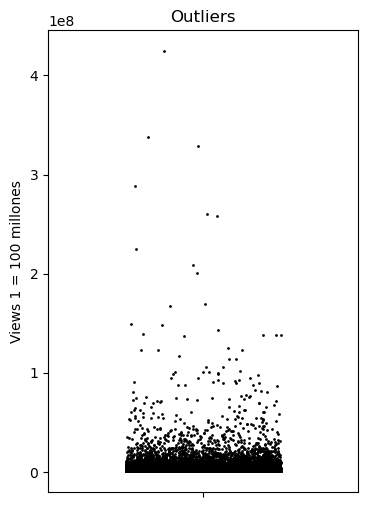

In [36]:
Q1 = df["views"].quantile(0.25)
Q3 = df["views"].quantile(0.75)
IQR = Q3 - Q1 #Rango intercuantílico
limite_outliers = Q3 + (1.5 * IQR)
df_outliers = df[df["views"] > limite_outliers]

plt.figure(figsize=(4, 6))
sns.stripplot(y=df_outliers["views"], color="black", jitter=0.25,size=2)

plt.title("Outliers")
plt.ylabel("Views 1 = 100 millones")
plt.show()

Vemos claramente los outliers y de cara al EDA los dejamos ya que según que planteamiento puede ser bueno quitarlos o no.

**Analisis univariado de variables categoricas**

In [37]:
df.category.value_counts(normalize=True)

category
Entertainment            0.295540
People & Blogs           0.172495
News & Politics          0.114208
Sports                   0.075157
Music                    0.067139
Comedy                   0.063496
Film & Animation         0.052818
Howto & Style            0.051295
Gaming                   0.029828
Education                0.021183
Science & Technology     0.019718
Autos & Vehicles         0.016894
Pets & Animals           0.012191
Travel & Events          0.004563
Shows                    0.003315
Nonprofits & Activism    0.000072
Movies                   0.000072
Trailers                 0.000014
Name: proportion, dtype: float64

Vemos que más de la mitad de los videos son de la categoría Entertainment, People & Blogs y News & Politics.

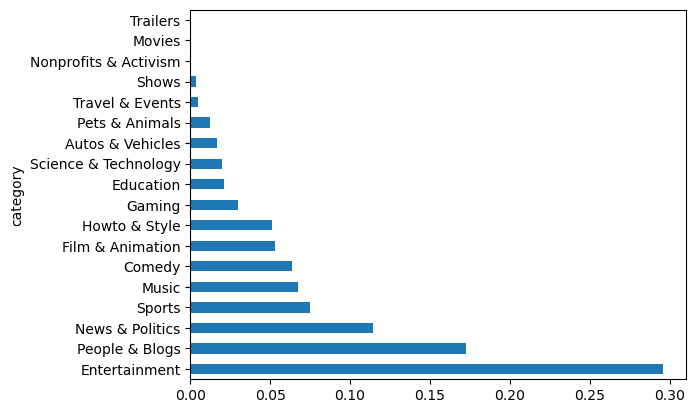

In [38]:
df.category.value_counts(normalize=True).plot.barh()
plt.show()

Vemos que las categorías Trailers, Movies y Nonprofits & Activism tienen muy pocos registros

In [39]:
df.category.value_counts()[["Trailers", "Movies", "Nonprofits & Activism"]]

category
Trailers                  3
Movies                   15
Nonprofits & Activism    15
Name: count, dtype: int64

Procedemos a eliminarlas ya que, con tan pocos vídeos, quitan más de lo que aportan a los modelos.

In [40]:
df.drop(df[df["category"].isin(["Trailers", "Movies", "Nonprofits & Activism"])].index, inplace=True)

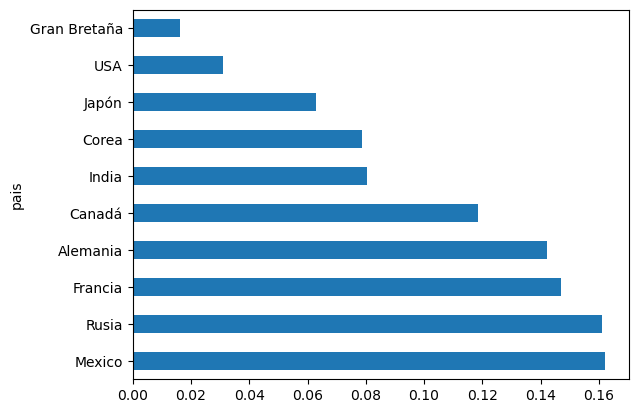

In [41]:
df.pais.value_counts(normalize=True).plot.barh()
plt.show()

Vemos que lo datos se centran sobre todo en los paises Rusia, Mexico, Alemania, Francia y Canada

In [42]:
df['comments_disabled'].value_counts()

comments_disabled
False    202599
True       4893
Name: count, dtype: int64

In [43]:
df['ratings_disabled'].value_counts()

ratings_disabled
False    202860
True       4632
Name: count, dtype: int64

In [44]:
df['video_error_or_removed'].value_counts()

video_error_or_removed
False    207387
True        105
Name: count, dtype: int64

In [45]:
df.drop('video_error_or_removed', axis=1, inplace=True)

Vemos que no tiene ningún valor esta variable por lo que la eliminamos ahora aquí e insertamos la actualización el fichero preprocess.

In [46]:
df.sort_values(by='views', ascending=False).head(10)

,trending_date,title,channel_title,publish_time,tags,views,likes,dislikes,comment_count,comments_disabled,ratings_disabled,category,pais,dias_desde_publicacion
150857,2018-04-07,Nicky Jam x J. Balvin - X (EQUIS) | Video Ofic...,NickyJamTV,2018-03-02,"[Bad Bunny, Amorfoda, Dura, Daddy Yankee, Ozun...",424538912,2818771,149275,99380,False,False,Music,Gran Bretaña,2
156905,2018-05-18,"Te Bote Remix - Casper, Nio García, Darell, Ni...",Flow La Movie,2018-04-11,"[Te Bote, Te Bote Remix, Flow La Movie, Ozuna,...",337621571,2581961,166549,113564,False,False,Music,Gran Bretaña,3
147990,2018-03-23,Bad Bunny - Amorfoda | Video Oficial,Bad Bunny,2018-02-15,"[Bad, Bunny, Bad Bunny, Video Oficial, Music V...",328860380,3823879,215530,225216,False,False,Music,Gran Bretaña,1
143607,2018-03-01,Ozuna x Romeo Santos - El Farsante Remix,Ozuna,2018-01-30,"[Ozuna, Reggaeton, Odisea, Odisea The Album, R...",288811992,1618180,151147,67506,False,False,Music,Gran Bretaña,2
160846,2018-06-11,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,2018-05-06,"[Childish Gambino, Rap, This Is America, mcDJ ...",259721696,5444541,379862,553371,False,False,Music,Gran Bretaña,1
148381,2018-03-25,Drake - God’s Plan,DrakeVEVO,2018-02-17,"[Drake new music, Drake Gods Plan, Drake God’s...",258164991,4737873,117198,301756,False,False,Music,Gran Bretaña,5
373540,2018-06-02,Childish Gambino - This Is America (Official V...,ChildishGambinoVEVO,2018-05-06,"[Childish Gambino, Rap, This Is America, mcDJ ...",225211923,5023450,343541,517232,False,False,Music,USA,2
158165,2018-05-26,Ariana Grande - No Tears Left To Cry,ArianaGrandeVevo,2018-04-20,"[Ariana, Grande, No, Tears, Left, To, Cry, Uni...",208876887,3394437,150086,259613,False,False,Music,Gran Bretaña,1
158168,2018-05-26,"Becky G, Natti Natasha - Sin Pijama (Official ...",BeckyGVEVO,2018-04-20,"[Becky G, Natti Natasha, Natti Natasha Music, ...",200862743,1668418,142569,97826,False,False,Music,Gran Bretaña,16
130634,2017-12-24,YouTube Rewind: The Shape of 2017 | #YouTubeRe...,YouTube Spotlight,2017-12-06,"[Rewind, Rewind 2017, youtube rewind 2017, #Yo...",169884583,3312868,1753274,845233,False,False,Entertainment,Gran Bretaña,1


Vemos que hay videos que han sido tendencia en diferentes países.

**Analisis multivariado**

In [47]:
df.pivot_table(index="pais", columns="category", values="views")

category,Autos & Vehicles,Comedy,Education,Entertainment,Film & Animation,Gaming,Howto & Style,Music,News & Politics,People & Blogs,Pets & Animals,Science & Technology,Shows,Sports,Travel & Events
pais,,,,,,,,,,,,,,,
Alemania,1.934430e+05,6.370840e+05,144247.965465,4.317013e+05,5.769994e+05,3.500935e+05,299676.137482,2.024636e+06,251877.822710,3.046419e+05,2.919468e+05,4.782260e+05,4.761774e+05,5.810094e+05,1.406850e+05
Canadá,4.816398e+05,8.724318e+05,459409.744538,7.317288e+05,9.819128e+05,7.185641e+05,663049.498428,3.167182e+06,307902.629232,5.765851e+05,5.519081e+05,9.654540e+05,5.817826e+05,8.038909e+05,3.963594e+05
Corea,1.070090e+05,3.513303e+05,118163.835443,4.361690e+05,4.645750e+05,2.492368e+05,382025.701887,1.774032e+06,134716.433151,1.941641e+05,1.925386e+05,2.568550e+06,1.082023e+05,6.916621e+05,2.669650e+05
Francia,6.090521e+04,3.730210e+05,129644.401421,3.449008e+05,3.556891e+05,2.414941e+05,182430.649468,1.144151e+06,117205.640959,1.904643e+05,1.643618e+05,4.041146e+05,5.236306e+05,4.004828e+05,5.457332e+04
Gran Bretaña,1.457632e+06,1.967056e+06,780772.000000,2.567087e+06,2.427073e+06,8.232446e+05,459653.915000,1.272255e+07,773944.250000,1.245253e+06,8.816329e+05,1.993358e+06,1.709880e+06,1.040113e+06,1.071762e+06
India,3.332654e+05,7.089324e+05,92438.020910,5.766691e+05,1.778204e+06,3.227187e+06,822677.317427,2.076332e+06,297426.506202,4.474413e+05,1.317532e+06,6.594729e+05,6.513166e+05,1.410399e+06,1.929078e+05
Japón,6.246815e+04,3.672608e+05,83620.590361,2.504836e+05,2.547108e+05,1.487873e+05,116843.424184,6.492050e+05,118175.592513,1.264726e+05,4.913599e+04,8.949333e+05,NaN,2.668928e+05,1.111057e+05
Mexico,1.372178e+05,4.076255e+05,78476.971014,2.464302e+05,3.091245e+05,3.692244e+05,164914.949683,9.706897e+05,138016.199127,1.275828e+05,4.638445e+05,2.927205e+05,2.181200e+04,3.248669e+05,1.348224e+05
Rusia,2.097492e+05,2.889580e+05,53657.478064,3.157302e+05,1.625047e+05,1.926100e+05,168871.154684,7.699724e+05,118024.212121,1.247756e+05,9.047947e+04,3.244303e+05,1.773477e+05,1.886925e+05,7.596964e+04


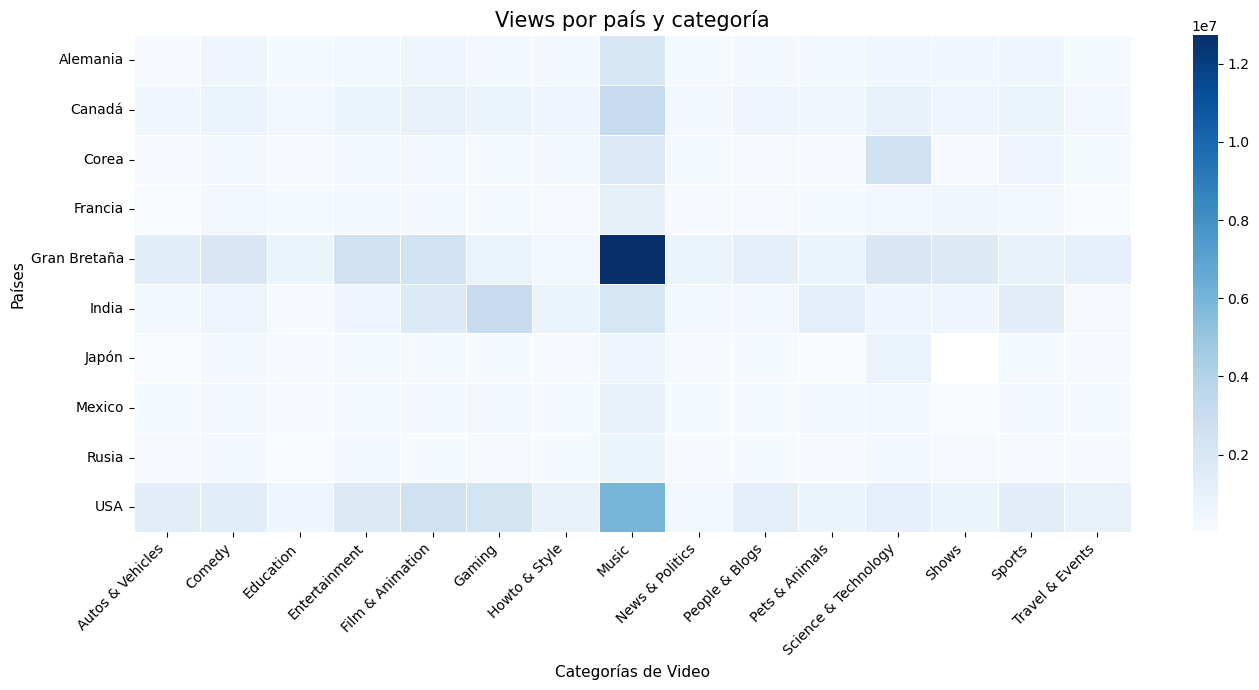

In [48]:
pivot_views = df.pivot_table(index="pais", columns="category", values="views")
plt.figure(figsize=(14, 7))

sns.heatmap(pivot_views, cmap="Blues", annot=False, linewidths=0.5)

plt.title("Views por país y categoría",fontsize=15)
plt.xlabel("Categorías de Video", fontsize=11)
plt.ylabel("Países", fontsize=11)
plt.xticks(rotation=45, ha="right") 

plt.tight_layout()
plt.show()

Vemos que las mayorias de visualizaciones se dan en Gran Bretaña y EEUU y que la categoría que más views suele tener es Music. El hecho de que un video sea de Gran Bretaña y de Musica puede ser relevante por ejemplo para el modelo, por lo que ambas categorías es bueno tenerlas en cuenta.

Vamos a desglosar comments_disabled	y ratings_disabled. Estas dos variables la mayoría del tiempo son False ya que lo normal es querer que la gente comente y haga like o dislike a tus videos. Vamos a ver en cuantos casos desactivaron ambas variables.

In [49]:
Desactivadas = df[(df["comments_disabled"] == True) & (df["ratings_disabled"] == True)]

In [50]:
Desactivadas.shape

(1421, 14)

In [51]:
Activadas = df[(df["comments_disabled"] == False) & (df["ratings_disabled"] == False)]

promedio_desactivadas = Desactivadas[["views"]].mean()# Calculamos el promedio de views para ambos grupos
promedio_activadas = Activadas[["views"]].mean()

# Juntamos ambos resultados en una pequeña tabla para compararlos
comparativa_directa = pd.DataFrame({"Ambas Activadas": promedio_activadas, "Ambas Desactivadas": promedio_desactivadas}).T #Transponemos para que se cambien columnas y filas

print(comparativa_directa)

                            views
Ambas Activadas     542451.836745
Ambas Desactivadas  466464.339901


Vemos que cuando los comentarios y los ratings están deshabilitados, los vídeos tienen menos visualizaciones de media (466.464 frente a 542.452). 

Una posible explicación es que el algoritmo de YouTube da más visibilidad a los vídeos que generan interacción (likes, dislikes y comentarios). Si el creador desactiva esas interacciones, el vídeo pierde señales de engagement y es menos recomendado. Además, este tipo de vídeos suele ser de nicho: canales de noticias o institucionales que evitan polémicas, contenido infantil o canales que prefieren no moderar comentarios. De hecho, entre los vídeos con ambas opciones desactivadas tiene más peso News & Politics (casi un 20 %) y destacan países como Japón, Francia e India.

Vimos que de media los videos suelen tardar unos 3 días en ser tendencia, aunque la mediana nos indica que suelen tardar alrededor de 1 dia. La dispersión es grande y se puede ver porque por ejemplo el vídeo máximo tardo 4215 dias en ser tendencia algo poco común.

Las conclusiones que podemos sacar son las siguientes:
1. Existe una relación clara entre los views, los coments y los likes/dislikes.
2. Entertainment, People & Blogs y News & Politics son las categorías que más destacan.
3. Un mismo vídeo puede ser viral en varios países.
4. Los vídeos con los comentarios y los ratings desactivados tienen menos visualizaciones (la mediana es unas 3,6 veces menor), probablemente porque al no generar interacción el algoritmo los recomienda menos.
5. Cruzando datos vemos que los videos que más views han tenido son de Musica fundamentalmente en Gran Bretaña. Tanto Gran Bretaña como el tipo Musica muestran ser una de las piezas fundamentales sobre las que giran las visualizaciones.

A continuación vamos a pasar a realizar punto por punto lo solicitado en los modelos.

**Predecir categoria del video**

Vamos a utilizar los modelos conocidos de scikit-learn sobre el dataset limpio que cargamos desde el fichero pickle.

In [52]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder,FunctionTransformer
from sklearn.compose import ColumnTransformer #lo usamo para ensamblar
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix

Incluimos comment_count junto al resto de variables numéricas. No incluimos comments_disabled ni ratings_disabled porque son casi siempre False y apenas aportan información al modelo.

In [53]:
X = df[["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion", "pais"]]
y = df["category"]

In [54]:
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)#conserva proporcion entre particiones

In [55]:
le = LabelEncoder()
le.fit(ytrain)
ytrain = le.transform(ytrain)
ytest = le.transform(ytest)

In [56]:
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
#Definimos el encoder para las variables que sean categoricas, en este caso solo será pais.

In [57]:
logaritmo = FunctionTransformer(np.log1p)
scaler = StandardScaler()
#Definimos las transformaciones numéricas para tratar los outliers

Regresión logística

In [58]:
from sklearn.linear_model import LogisticRegression

In [59]:
lr = LogisticRegression(max_iter=1000)#subimos las iteraciones porque con las 100 por defecto el modelo no terminaba de ajustarse

Creamos un pipeline numérico para incluirlo en el ensamblador de Column Transformer ya que según el modelo los outliers pueden o no ser relevantes de quitar.

In [60]:
pipeline_num = Pipeline([('log', logaritmo),('scaler', scaler)])

In [61]:
preprocess_lr = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [62]:
pipeline_lr = Pipeline(steps=[('preprocesamiento', preprocess_lr),
                              ('modelo', lr)])

In [63]:
pipeline_lr.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', LogisticRegression(max_iter=1000))])

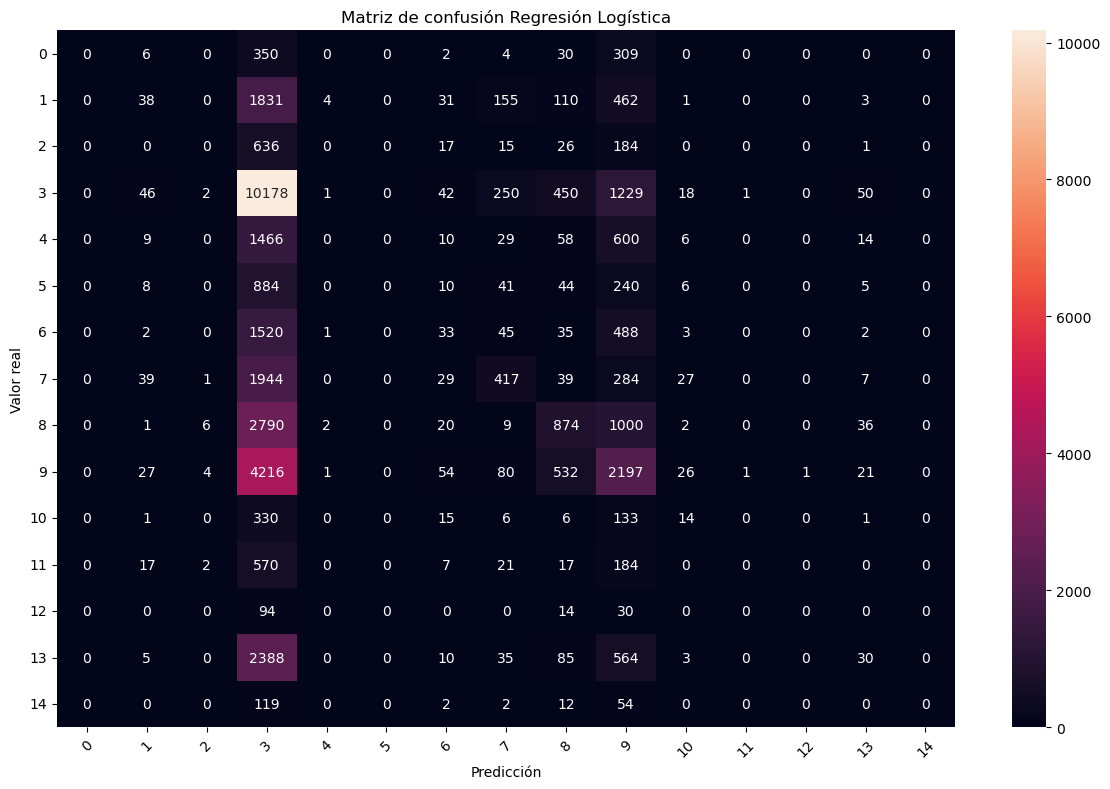

In [64]:
#Matriz confusión regresión logística.

y_pred_lr = pipeline_lr.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_lr)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión Regresión Logística")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vemos en la matriz que el modelo está muy descompensado hacia las clases 3 y 9. Es posible que haya un desbalanceo en el cual haya clases más dominantes y clases con menos registros y por ello, el modelo tienda a no predecir nunca las no dominantes. Lo podemos ver a continuación.

In [65]:
df["category"].value_counts()

category
Entertainment           61332
People & Blogs          35797
News & Politics         23701
Sports                  15597
Music                   13933
Comedy                  13177
Film & Animation        10961
Howto & Style           10645
Gaming                   6190
Education                4396
Science & Technology     4092
Autos & Vehicles         3506
Pets & Animals           2530
Travel & Events           947
Shows                     688
Name: count, dtype: int64

Random Forest

En Random Forest no es necesario tratar los outliers ni escalar las variables, ya que los árboles dividen los datos por umbrales y no les afecta la magnitud de los valores. Por tanto, dejamos las variables numéricas tal cual.

In [66]:
from sklearn.ensemble import RandomForestClassifier

In [67]:
rf = RandomForestClassifier(random_state=42)

In [68]:
preprocess_rf = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("numericas", "passthrough",
     ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])#ponemos esto ya que con column transformer hay que incluirlas aunque no les hagamos nada.
])

In [69]:
pipeline_rf = Pipeline(steps=[('preprocesamiento', preprocess_rf),
                              ('modelo', rf)])

In [70]:
pipeline_rf.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('numericas', 'passthrough',
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', RandomForestClassifier(random_state=42))])

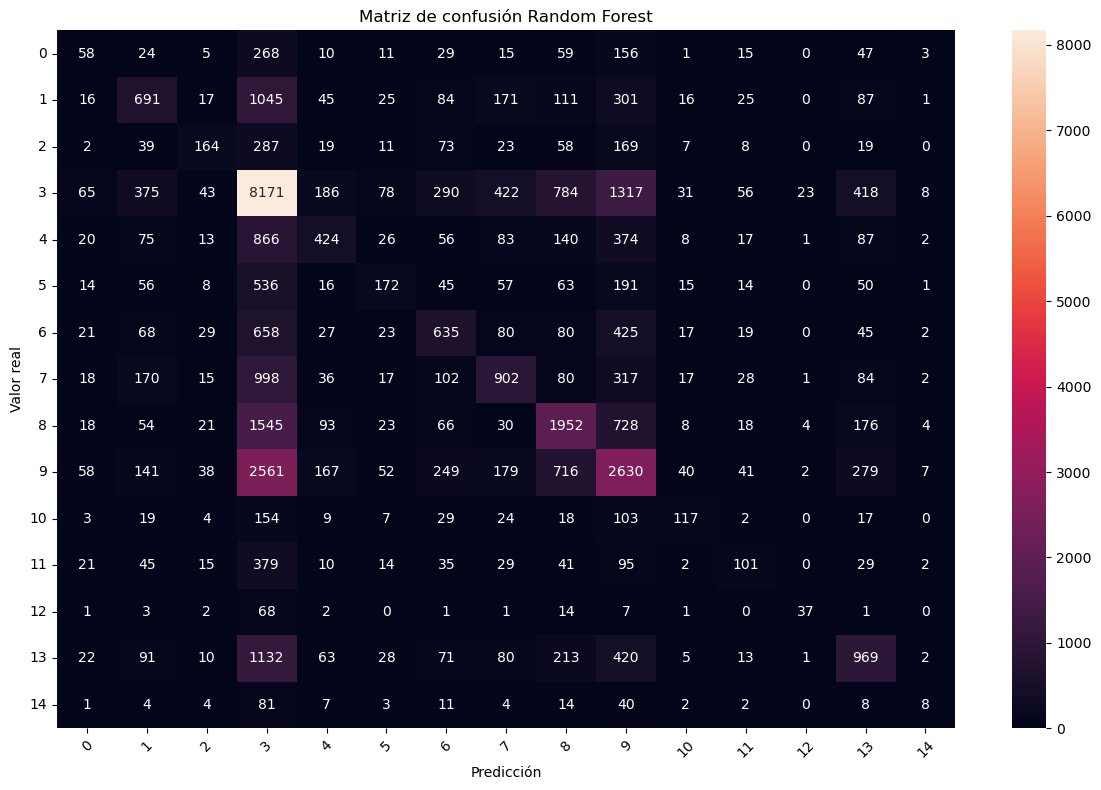

In [71]:
#Matriz de confusión random forest

y_pred_rf = pipeline_rf.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_rf)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

KNN

In [72]:
from sklearn.neighbors import KNeighborsClassifier

In [73]:
knn = KNeighborsClassifier()

In [74]:
preprocess_knn = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [75]:
pipeline_knn = Pipeline(steps=[('preprocesamiento', preprocess_knn),
                              ('modelo', knn)])

In [76]:
pipeline_knn.fit(Xtrain, ytrain)

Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', KNeighborsClassifier())])

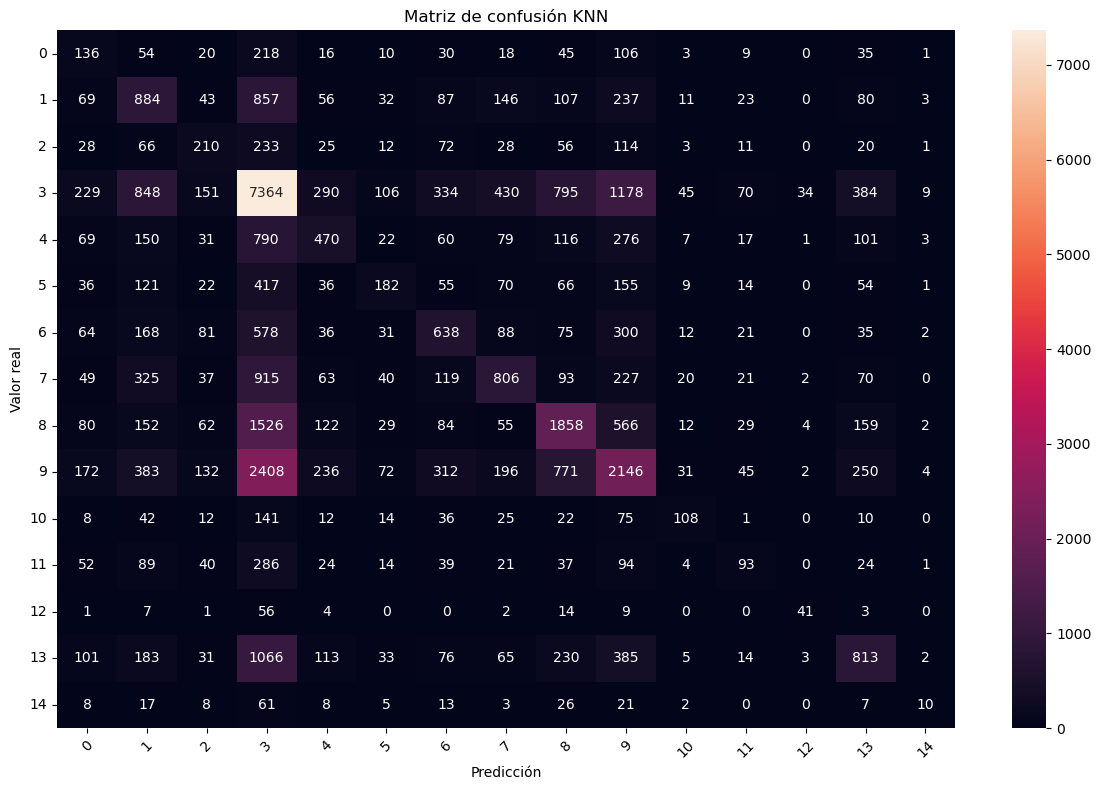

In [77]:
#Matriz de confusión KNN

y_pred_knn = pipeline_knn.predict(Xtest)

cm = confusion_matrix(ytest, y_pred_knn)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión KNN")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Vemos que aquí el modelo acierta más que la Regresión Logística y aunque sigue teniendo la misma tendencia, los datos de aciertos en distintas variables están más repartidos. Hay un claro desbalanceo de clases.

SVM

In [78]:
from sklearn.svm import SVC

In [79]:
svm = SVC(kernel='rbf', cache_size=1000, tol=1e-1, shrinking=True, max_iter=1000)  
# Tras varios intentos sabiendo que este no sería el modelo, optimizamos para que lo ejecute y se procese rápido

In [80]:
preprocess_svm = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais"]),
    ("num_procesadas", pipeline_num, ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion"])])

In [81]:
pipeline_svm = Pipeline(steps=[("preprocesamiento", preprocess_svm),
                              ("modelo", svm)])

In [82]:
pipeline_svm.fit(Xtrain, ytrain)

c:\Users\luci_\anaconda3\Lib\site-packages\sklearn\svm\_base.py:297: ConvergenceWarning: Solver terminated early (max_iter=1000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Pipeline(steps=[('preprocesamiento',
                 ColumnTransformer(transformers=[('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['pais']),
                                                 ('num_procesadas',
                                                  Pipeline(steps=[('log',
                                                                   FunctionTransformer(func=<ufunc 'log1p'>)),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['views', 'likes', 'dislikes',
                                                   'comment_count',
                                                   'dias_desde_publicacion'])])),
                ('modelo', SVC(cache_size=1000, max_iter=1000, tol=0.1))])

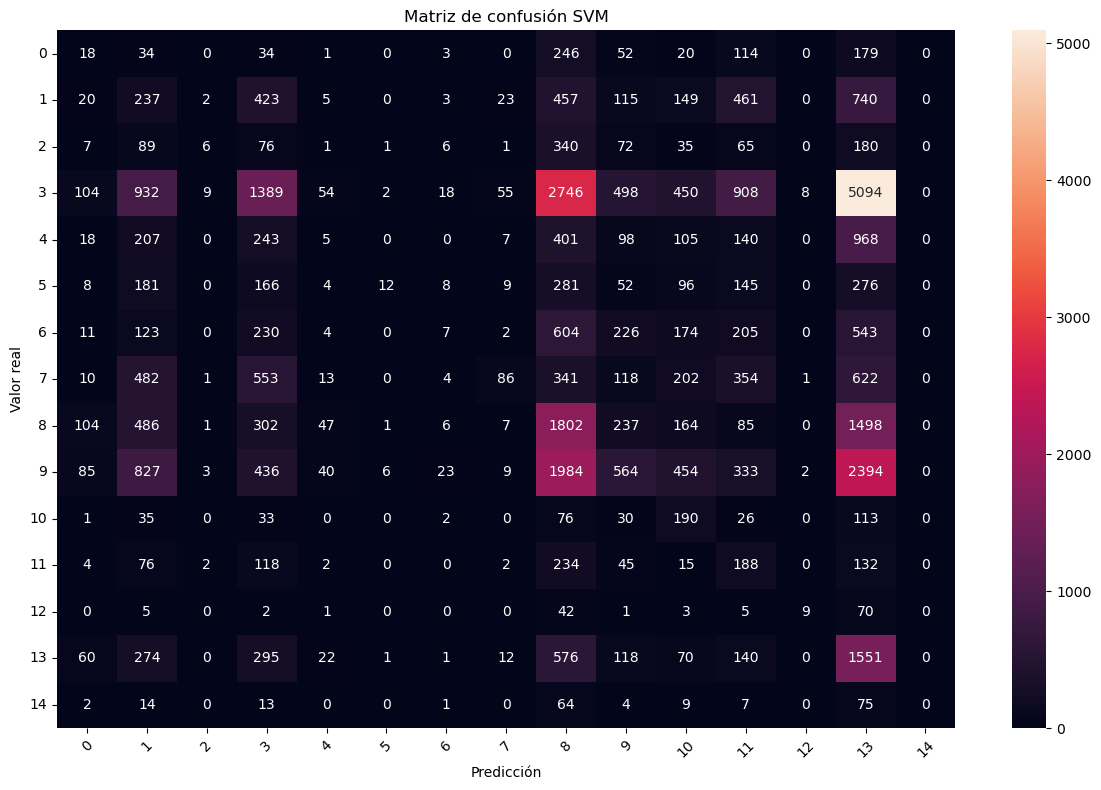

In [83]:
#Matriz de confusión SVM

y_pred_svm = pipeline_svm.predict(Xtest)
cm = confusion_matrix(ytest, y_pred_svm)

plt.figure(figsize=(12, 8))
sns.heatmap(
    cm,
    annot=True,          # muestra los valores dentro de cada celda
    fmt="d",            # formato entero
    cbar=True           # barra de color
)
plt.title("Matriz de confusión SVM")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Resumen de las matrices de confusión:**

- **Regresión Logística:** predice casi siempre la clase 3 y, en menor medida, la 9. Prácticamente no acierta las clases minoritarias y algunas no las llega a predecir nunca.
- **Random Forest:** es el más equilibrado. Sigue favoreciendo la clase 3, pero predice todas las clases y acierta mejor la 8 y la 9.
- **KNN:** comportamiento muy parecido a Random Forest, algo peor en general, aunque reparte un poco más los aciertos entre clases.
- **SVM:** al no terminar de ajustarse, se desvía hacia las clases 13 y 8 y falla la mayoría del resto, por eso es el peor.

En todos los modelos el desbalanceo de clases hace que las clases mayoritarias dominen las predicciones.

Vistas las matrices de confusión, procedemos a comparar todas las métricas para ver los valores más altos.

In [84]:
clasification = {
    "Modelo": ["Regresión Logística", "Random Forest", "KNN", "SVM"],
    "Accuracy": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest, y_pred_svm, zero_division=0,output_dict=True)["accuracy"]
    ],
    "F1 Macro": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["macro avg"]["f1-score"]
    ],
    "F1 Weighted": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["weighted avg"]["f1-score"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["weighted avg"]["f1-score"]
    ],
    "Recall Macro": [
        classification_report(ytest, y_pred_lr,zero_division=0, output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_rf, zero_division=0,output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["recall"],
        classification_report(ytest, y_pred_svm, zero_division=0,output_dict=True)["macro avg"]["recall"]
    ],
    "Precision Macro": [
        classification_report(ytest, y_pred_lr, zero_division=0,output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_rf,zero_division=0, output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_knn,zero_division=0, output_dict=True)["macro avg"]["precision"],
        classification_report(ytest, y_pred_svm,zero_division=0, output_dict=True)["macro avg"]["precision"]
    ]
}

df_clasification = pd.DataFrame(clasification)

metricas = ["Accuracy", "F1 Macro", "F1 Weighted", "Recall Macro", "Precision Macro"]

df_clasification = df_clasification.sort_values(by="F1 Macro", ascending=False)

tabla_clasification = df_clasification.style#usamos esto para personalizar la tabla

for col in metricas:
    tabla_clasification = tabla_clasification.highlight_max(subset=[col], props="font-weight: bold; font-size: 16px;")

tabla_clasification.hide()#ocultamos el indice

Modelo,Accuracy,F1 Macro,F1 Weighted,Recall Macro,Precision Macro
Random Forest,0.410395,0.293292,0.390884,0.260452,0.371098
KNN,0.379744,0.281494,0.368319,0.263229,0.330483
Regresión Logística,0.332080,0.090639,0.242494,0.102518,0.132705
SVM,0.146124,0.084028,0.125399,0.127226,0.189490


Elegimos el modelo Random Forest. Procedemos a optimizarlo con RandomizedSearchCV en lugar de GridSearchCV, ya que al intentarlo con Grid el coste computacional era enorme.

In [85]:
from sklearn.model_selection import RandomizedSearchCV #No utilizamos Grid ya que al intentarlos el coste computacional era enorme 
from sklearn.metrics import f1_score, classification_report 

In [ ]:
param_dist = {
    "modelo__n_estimators": [100, 150],
    "modelo__criterion": ["gini", "entropy"],#no utilizamos log_loss porque se basan en la misma medida
    "modelo__max_depth": [12, 20, None],
    "modelo__min_samples_split": [2, 5, 10],
    "modelo__min_samples_leaf": [1, 2, 4],
    "modelo__max_features": ["sqrt", "log2", 0.5],
    "modelo__class_weight": [None, "balanced", "balanced_subsample"],
    "modelo__bootstrap": [True],
    "modelo__max_samples": [0.7, 0.8]
}

grid_search_rf = RandomizedSearchCV(
    estimator=pipeline_rf,         
    param_distributions=param_dist,
    n_iter=12,
    scoring="f1_macro",
    n_jobs=1,
    pre_dispatch="n_jobs",
    verbose=1,
    cv=2,
    random_state=42,
    refit=True
)

grid_search_rf.fit(Xtrain, ytrain)

rf_optimo = grid_search_rf.best_estimator_

print("Best parameters:", grid_search_rf.best_params_)
print("Best CV f1_macro:", grid_search_rf.best_score_)

y_pred_train = rf_optimo.predict(Xtrain)
y_pred_test = rf_optimo.predict(Xtest)

print("\nTrain f1_macro:", f1_score(ytrain, y_pred_train, average="macro"))
print(classification_report(ytrain, y_pred_train))

print("\nTest f1_macro:", f1_score(ytest, y_pred_test, average="macro"))
print(classification_report(ytest, y_pred_test))

Fitting 2 folds for each of 12 candidates, totalling 24 fits


Añadimos el Random Forest optimizado a la tabla comparativa para ver la mejora respecto al resto de modelos.

In [ ]:
report_rf_optimo = classification_report(ytest, y_pred_test, zero_division=0, output_dict=True)

fila_rf_optimo = pd.DataFrame({
    "Modelo": ["Random Forest optimizado"],
    "Accuracy": [report_rf_optimo["accuracy"]],
    "F1 Macro": [report_rf_optimo["macro avg"]["f1-score"]],
    "F1 Weighted": [report_rf_optimo["weighted avg"]["f1-score"]],
    "Recall Macro": [report_rf_optimo["macro avg"]["recall"]],
    "Precision Macro": [report_rf_optimo["macro avg"]["precision"]]
})

df_comparativa = pd.concat([df_clasification, fila_rf_optimo], ignore_index=True)

df_comparativa = df_comparativa.sort_values(by="F1 Macro", ascending=False)

tabla_comparativa = df_comparativa.style

for col in metricas:
    tabla_comparativa = tabla_comparativa.highlight_max(subset=[col], props="font-weight: bold; font-size: 16px;")

tabla_comparativa.hide()#ocultamos el indice

Tras la optimización con RandomizedSearchCV, el mejor modelo obtiene un F1 Macro en test de 0,32 frente al 0,29 del Random Forest por defecto, por lo que la optimización mejora el modelo, sobre todo en la detección de las categorías minoritarias gracias a class_weight="balanced_subsample". A cambio, la accuracy baja ligeramente (0,39 frente a 0,41), ya que el modelo deja de predecir con tanta frecuencia las categorías mayoritarias como Entertainment. Aun así, el modelo presenta sobreajuste: el F1 Macro en train es 0,83 frente a 0,32 en test. En general, con las variables numéricas disponibles es difícil predecir la categoría de un vídeo con gran precisión.

**Reto opcional para subir nota: Crear un algoritmo de clasificación que intente averiguar lo mejor posible si los comentarios o los ratings estarán deshabilitados por parte del creador del vídeo en base al resto de la información. Al ser una clasificación altamente desbalanceada se valorará no solo obtener una alta precisión, sino también estudiar en una matriz de confusión si se sega excesivamente hacia la clase mayoritaria y en el caso de que ocurra intentar mitigar este hecho.**

Vimos en el EDA, al comparar los vídeos con los comentarios y los ratings activados y desactivados, que los vídeos con ambas opciones desactivadas tienen menos visualizaciones. Esto nos dice algo importante sobre qué variables podemos usar.

Por un lado, views mide el alcance del vídeo y existe independientemente de la decisión del creador: un vídeo sigue acumulando visualizaciones tenga o no los comentarios y los ratings desactivados. Por eso sí nos puede ayudar a predecir.

Por otro lado, likes, dislikes y comment_count no miden lo mismo en estos vídeos. Si el creador desactiva los comentarios, el público no puede comentar y comment_count se queda en 0. Si desactiva los ratings, no se puede dar like ni dislike, y likes y dislikes se quedan en 0. Es decir, en estos vídeos esas variables no reflejan cómo de popular es el vídeo, sino directamente la decisión que queremos predecir. Usarlas sería como darle la respuesta al modelo.

En el EDA creamos el dataframe Desactivadas con los vídeos que tenían los comentarios y los ratings desactivados. Si miramos sus likes, dislikes y comment_count, vemos que todos valen 0:

In [ ]:
Desactivadas[["likes", "dislikes", "comment_count"]].max()

Pero en el reto queremos predecir si están desactivados los comentarios o los ratings, no solo ambos a la vez. Comprobamos qué pasa en cada caso por separado:

In [ ]:
print(df[df["comments_disabled"] == True]["comment_count"].max())
print(df[df["ratings_disabled"] == True][["likes", "dislikes"]].max())

Por tanto, likes, dislikes y comment_count no nos sirven para predecir: no son una causa de que el creador desactive los comentarios o los ratings, sino una consecuencia. Si las usáramos, el modelo acertaría casi siempre, pero sería hacer trampa, ya que con un vídeo nuevo no sabríamos esos valores antes de que el creador tomara la decisión. Por eso usamos solo views, dias_desde_publicacion, pais y category.

In [ ]:
X_reto = df[["views", "dias_desde_publicacion", "pais", "category"]]
y_reto = (df["comments_disabled"] | df["ratings_disabled"]).astype(int)#1 si tiene desactivados los comentarios o los ratings, 0 si no. Al pasarlo a int ya es numérico, por lo que no necesitamos LabelEncoder

In [ ]:
print(y_reto.value_counts())

En y_reto, el valor 1 indica que el vídeo tiene desactivados los comentarios, los ratings o ambos, y el valor 0 que tiene las dos opciones activadas.

In [ ]:
Xtrain_reto, Xtest_reto, ytrain_reto, ytest_reto = train_test_split(X_reto, y_reto, test_size=0.2, random_state=42, stratify=y_reto)#conserva proporcion entre particiones

Regresión logística

In [ ]:
lr_reto = LogisticRegression(max_iter=1000)

In [ ]:
preprocess_lr_reto = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "dias_desde_publicacion"])])

In [ ]:
pipeline_lr_reto = Pipeline(steps=[('preprocesamiento', preprocess_lr_reto),
                                   ('modelo', lr_reto)])

In [ ]:
pipeline_lr_reto.fit(Xtrain_reto, ytrain_reto)

In [ ]:
y_pred_lr_reto = pipeline_lr_reto.predict(Xtest_reto)

Random Forest

In [ ]:
rf_reto = RandomForestClassifier(random_state=42)

In [ ]:
preprocess_rf_reto = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("numericas", "passthrough", ["views", "dias_desde_publicacion"])])

In [ ]:
pipeline_rf_reto = Pipeline(steps=[('preprocesamiento', preprocess_rf_reto),
                                   ('modelo', rf_reto)])

In [ ]:
pipeline_rf_reto.fit(Xtrain_reto, ytrain_reto)

In [ ]:
y_pred_rf_reto = pipeline_rf_reto.predict(Xtest_reto)

KNN

In [ ]:
knn_reto = KNeighborsClassifier()

In [ ]:
preprocess_knn_reto = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "dias_desde_publicacion"])])

In [ ]:
pipeline_knn_reto = Pipeline(steps=[('preprocesamiento', preprocess_knn_reto),
                                    ('modelo', knn_reto)])

In [ ]:
pipeline_knn_reto.fit(Xtrain_reto, ytrain_reto)

In [ ]:
y_pred_knn_reto = pipeline_knn_reto.predict(Xtest_reto)

SVM

In [ ]:
svm_reto = SVC(kernel='rbf', cache_size=1000, tol=1e-1, shrinking=True, max_iter=1000)

In [ ]:
preprocess_svm_reto = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "dias_desde_publicacion"])])

In [ ]:
pipeline_svm_reto = Pipeline(steps=[('preprocesamiento', preprocess_svm_reto),
                                    ('modelo', svm_reto)])

In [ ]:
pipeline_svm_reto.fit(Xtrain_reto, ytrain_reto)

In [ ]:
y_pred_svm_reto = pipeline_svm_reto.predict(Xtest_reto)

Comparamos las métricas de los cuatro modelos. Al estar las clases tan desbalanceadas nos fijamos sobre todo en las métricas de la clase 1 (vídeos con comentarios o ratings desactivados), ya que la accuracy puede salir alta aunque el modelo no detecte ninguno.

In [ ]:
clasification_reto = {
    "Modelo": ["Regresión Logística", "Random Forest", "KNN", "SVM"],
    "Accuracy": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["accuracy"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["accuracy"]
    ],
    "F1 Macro": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["macro avg"]["f1-score"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["macro avg"]["f1-score"]
    ],
    "Recall clase 1": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["1"]["recall"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["1"]["recall"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["1"]["recall"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["1"]["recall"]
    ],
    "Precision clase 1": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["1"]["precision"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["1"]["precision"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["1"]["precision"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["1"]["precision"]
    ],
    "F1 clase 1": [
        classification_report(ytest_reto, y_pred_lr_reto, zero_division=0, output_dict=True)["1"]["f1-score"],
        classification_report(ytest_reto, y_pred_rf_reto, zero_division=0, output_dict=True)["1"]["f1-score"],
        classification_report(ytest_reto, y_pred_knn_reto, zero_division=0, output_dict=True)["1"]["f1-score"],
        classification_report(ytest_reto, y_pred_svm_reto, zero_division=0, output_dict=True)["1"]["f1-score"]
    ]
}

df_clasification_reto = pd.DataFrame(clasification_reto)

metricas_reto = ["Accuracy", "F1 Macro", "Recall clase 1", "Precision clase 1", "F1 clase 1"]

df_clasification_reto = df_clasification_reto.sort_values(by="F1 clase 1", ascending=False)

tabla_clasification_reto = df_clasification_reto.style

for col in metricas_reto:
    tabla_clasification_reto = tabla_clasification_reto.highlight_max(subset=[col], props="font-weight: bold; font-size: 16px;")

tabla_clasification_reto.hide()#ocultamos el indice

Vemos que todos los modelos están sesgados hacia la clase mayoritaria. El caso más claro es la Regresión Logística, que tiene la accuracy más alta (96 %) pero no detecta ningún vídeo con los comentarios o los ratings desactivados, ya que predice siempre 0. Elegimos Random Forest porque es el que obtiene mejor F1 en la clase 1, aunque solo detecta un 9 % de estos vídeos. A continuación intentaremos mitigar este sesgo.

Optimizamos el Random Forest con GridSearchCV. A diferencia de la predicción de categoría, aquí no buscamos entre muchos parámetros, sino que nos centramos en los que afectan directamente al desbalanceo de clases. Como son pocas combinaciones, podemos probarlas todas con Grid sin un coste computacional excesivo:

- class_weight: con "balanced" el modelo da más peso a los errores en la clase minoritaria (1), de forma inversamente proporcional a su frecuencia. Así deja de compensarle predecir siempre 0.
- min_samples_leaf: número mínimo de vídeos en cada hoja del árbol. Con 1, los árboles crecen hasta memorizar cada vídeo y el peso de las clases apenas influye. Con hojas más grandes, cada hoja agrupa varios vídeos y el peso de la clase minoritaria sí cambia la decisión.
- max_depth: profundidad máxima de los árboles. Limitarla tiene un efecto parecido al anterior, ya que evita que los árboles memoricen los datos de entrenamiento.

Como métrica usamos el F1 de la clase 1, ya que es la clase que queremos detectar.

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid_reto = {
    "modelo__class_weight": [None, "balanced"],
    "modelo__min_samples_leaf": [1, 20, 50],
    "modelo__max_depth": [12, None]
}

grid_search_rf_reto = GridSearchCV(
    estimator=pipeline_rf_reto,
    param_grid=param_grid_reto,
    scoring="f1",#f1 de la clase 1
    n_jobs=1,
    pre_dispatch="n_jobs",
    verbose=1,
    cv=2,
    refit=True
)

grid_search_rf_reto.fit(Xtrain_reto, ytrain_reto)

rf_optimo_reto = grid_search_rf_reto.best_estimator_

print("Best parameters:", grid_search_rf_reto.best_params_)
print("Best CV f1 clase 1:", grid_search_rf_reto.best_score_)

y_pred_train_reto = rf_optimo_reto.predict(Xtrain_reto)
y_pred_test_reto = rf_optimo_reto.predict(Xtest_reto)

print("\nTrain f1 clase 1:", f1_score(ytrain_reto, y_pred_train_reto))
print(classification_report(ytrain_reto, y_pred_train_reto))

print("\nTest f1 clase 1:", f1_score(ytest_reto, y_pred_test_reto))
print(classification_report(ytest_reto, y_pred_test_reto))

Con GridSearchCV el mejor modelo usa class_weight="balanced", min_samples_leaf=20 y sin límite de profundidad, lo que confirma que el peso de la clase minoritaria solo tiene efecto cuando las hojas agrupan varios vídeos. El recall de la clase 1 pasa del 9 % al 52 %, es decir, ahora el modelo detecta más de la mitad de los vídeos con los comentarios o los ratings desactivados, y el F1 de la clase 1 sube de 0,09 a 0,16. A cambio, la accuracy baja del 93 % al 79 %, ya que el modelo deja de predecir siempre la clase mayoritaria y aparecen más falsos positivos. La precisión se mantiene en torno al 10 %, lo que indica que, sin las variables que delatan la respuesta, la información disponible para predecir esta decisión del creador es limitada. Además, el F1 en validación cruzada (0,165) y en test (0,162) es muy parecido, por lo que el resultado es estable.

Comparamos las matrices de confusión del Random Forest base y del optimizado con Grid para ver si el modelo se sesga hacia la clase mayoritaria y si hemos conseguido mitigarlo.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(confusion_matrix(ytest_reto, y_pred_rf_reto), annot=True, fmt="d", cbar=False, ax=axes[0])
axes[0].set_title("Matriz de confusión Random Forest base")
axes[0].set_xlabel("Predicción")
axes[0].set_ylabel("Valor real")

sns.heatmap(confusion_matrix(ytest_reto, y_pred_test_reto), annot=True, fmt="d", cbar=False, ax=axes[1])
axes[1].set_title("Matriz de confusión Random Forest con Grid")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Valor real")

plt.tight_layout()
plt.show()

**Conclusiones de las matrices de confusión:**

- **Random Forest base:** el modelo está claramente sesgado hacia la clase mayoritaria. De los 1.621 vídeos con los comentarios o los ratings desactivados, solo detecta 146 y clasifica como 0 los otros 1.475.
- **Random Forest con Grid:** el sesgo se mitiga. Detecta 841 de los 1.621 vídeos desactivados, más de la mitad, y los que se le escapan bajan de 1.475 a 780.
- **El coste:** los falsos positivos, es decir, vídeos con todo activado que el modelo marca como desactivados, suben de 1.317 a 7.890. Por eso baja la accuracy.

En resumen, hemos conseguido que el modelo deje de ignorar la clase minoritaria, a cambio de más falsas alarmas. Si el objetivo es detectar los vídeos en los que el creador desactivará los comentarios o los ratings, es preferible un modelo que detecte más de la mitad de ellos aunque se equivoque más, que uno con mayor accuracy que apenas detecta ninguno.

**Predecir el número de likes**

En el reto vimos que, cuando los ratings están desactivados, los likes valen siempre 0, ya que el público no puede darle a "Me gusta". En estos vídeos no hay unos likes que predecir, por lo que los eliminamos de este apartado. Si los dejáramos y usáramos ratings_disabled como variable, sería darle la respuesta al modelo, igual que explicamos en el reto.

In [ ]:
df_likes = df[df["ratings_disabled"] == False]

X_likes = df_likes[["views", "comment_count", "dislikes", "dias_desde_publicacion", "comments_disabled", "pais", "category"]]
y_likes = df_likes["likes"]

In [ ]:
Xtrain_likes, Xtest_likes, ytrain_likes, ytest_likes = train_test_split(X_likes, y_likes, test_size=0.2, random_state=42)#al ser regresión no usamos stratify

Igual que las variables numéricas, la variable likes está muy sesgada: la media es de unos 16.000 likes, la mediana de unos 1.700 y el máximo supera los 5,6 millones. Por eso aplicamos también el logaritmo a la y. Para ello usamos TransformedTargetRegressor, que entrena el modelo con log1p(likes) y al predecir deshace el logaritmo con expm1, de forma que las predicciones y las métricas vuelven a estar en número de likes.

Regresión Lineal

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor

In [ ]:
lr_likes = TransformedTargetRegressor(regressor=LinearRegression(), func=np.log1p, inverse_func=np.expm1)

In [ ]:
preprocess_lr_likes = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "comment_count", "dislikes", "dias_desde_publicacion"]),
    ("booleana", "passthrough", ["comments_disabled"])])

In [ ]:
pipeline_lr_likes = Pipeline(steps=[("preprocesamiento", preprocess_lr_likes),
                                    ("modelo", lr_likes)])

In [ ]:
pipeline_lr_likes.fit(Xtrain_likes, ytrain_likes)

In [ ]:
y_pred_lr_likes = pipeline_lr_likes.predict(Xtest_likes)

Perceptrón Multicapa

In [ ]:
from sklearn.neural_network import MLPRegressor

In [ ]:
mlp_likes = TransformedTargetRegressor(regressor=MLPRegressor(random_state=42), func=np.log1p, inverse_func=np.expm1)

In [ ]:
preprocess_mlp_likes = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("num_procesadas", pipeline_num, ["views", "comment_count", "dislikes", "dias_desde_publicacion"]),
    ("booleana", "passthrough", ["comments_disabled"])])

In [ ]:
pipeline_mlp_likes = Pipeline(steps=[("preprocesamiento", preprocess_mlp_likes),
                                     ("modelo", mlp_likes)])

In [ ]:
pipeline_mlp_likes.fit(Xtrain_likes, ytrain_likes)

In [ ]:
y_pred_mlp_likes = pipeline_mlp_likes.predict(Xtest_likes)

Random Forest

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf_likes = TransformedTargetRegressor(regressor=RandomForestRegressor(random_state=42), func=np.log1p, inverse_func=np.expm1)

En Random Forest no es necesario tratar los outliers ni escalar las variables, ya que los árboles dividen los datos por umbrales y no les afecta la magnitud de los valores. Por tanto, dejamos las variables numéricas tal cual.

In [ ]:
preprocess_rf_likes = ColumnTransformer(transformers=[
    ("encoder", encoder, ["pais", "category"]),
    ("numericas", "passthrough", ["views", "comment_count", "dislikes", "dias_desde_publicacion", "comments_disabled"])])

In [ ]:
pipeline_rf_likes = Pipeline(steps=[("preprocesamiento", preprocess_rf_likes),
                                    ("modelo", rf_likes)])

In [ ]:
pipeline_rf_likes.fit(Xtrain_likes, ytrain_likes)

In [ ]:
y_pred_rf_likes = pipeline_rf_likes.predict(Xtest_likes)

Comparamos las métricas de los tres modelos. Al ser una regresión no usamos classification_report, sino métricas que miden cuánto se aleja la predicción del valor real:

- MAE: error medio en número de likes.
- RMSE: parecido al MAE, pero castiga más los errores grandes.
- R2: proporción de la variación de los likes que explica el modelo (1 es perfecto, 0 es como predecir siempre la media).

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
regresion = {
    "Modelo": ["Regresión Lineal", "Perceptrón Multicapa", "Random Forest"],
    "MAE": [
        mean_absolute_error(ytest_likes, y_pred_lr_likes),
        mean_absolute_error(ytest_likes, y_pred_mlp_likes),
        mean_absolute_error(ytest_likes, y_pred_rf_likes)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(ytest_likes, y_pred_lr_likes)),
        np.sqrt(mean_squared_error(ytest_likes, y_pred_mlp_likes)),
        np.sqrt(mean_squared_error(ytest_likes, y_pred_rf_likes))
    ],
    "R2": [
        r2_score(ytest_likes, y_pred_lr_likes),
        r2_score(ytest_likes, y_pred_mlp_likes),
        r2_score(ytest_likes, y_pred_rf_likes)
    ]
}

df_regresion = pd.DataFrame(regresion)

df_regresion = df_regresion.sort_values(by="R2", ascending=False)

tabla_regresion = df_regresion.style

tabla_regresion = tabla_regresion.highlight_min(subset=["MAE", "RMSE"], props="font-weight: bold; font-size: 16px;")#en MAE y RMSE cuanto menor mejor
tabla_regresion = tabla_regresion.highlight_max(subset=["R2"], props="font-weight: bold; font-size: 16px;")#en R2 cuanto mayor mejor

tabla_regresion.hide()#ocultamos el indice

**Conclusiones de la comparativa:**

- **Random Forest:** es el que mejor predice. Acierta el 95 % del comportamiento de los likes y, de media, se equivoca en unos 4.900 likes por vídeo.
- **Perceptrón Multicapa:** acierta algo más de la mitad (54 %) y se equivoca en unos 11.400 likes de media, más del doble que Random Forest.
- **Regresión Lineal:** es el que peor predice. Solo acierta el 17 % y se equivoca en unos 27.000 likes de media. Esto pasa porque los likes no suben de forma proporcional al resto de variables, y una recta no es capaz de seguir esa relación.

En los tres modelos el RMSE es mucho más alto que el MAE. Esto quiere decir que en la mayoría de vídeos el modelo se acerca bastante, pero en unos pocos vídeos virales con millones de likes falla por mucho.

Nos quedamos con Random Forest y vamos a buscar la mejor combinación de sus parámetros. Igual que en la predicción de categoría, usamos RandomizedSearchCV, que prueba solo algunas combinaciones al azar, en lugar de GridSearchCV, que las prueba todas y tardaría demasiado. Para elegir la mejor combinación nos fijamos en el R2.

In [ ]:
param_dist_likes = {
    "modelo__regressor__n_estimators": [100, 150],
    "modelo__regressor__max_depth": [12, 20, None],
    "modelo__regressor__min_samples_split": [2, 5, 10],
    "modelo__regressor__min_samples_leaf": [1, 2, 4],
    "modelo__regressor__max_features": ["sqrt", "log2", 0.5, 1.0],
    "modelo__regressor__bootstrap": [True],
    "modelo__regressor__max_samples": [0.7, 0.8]
}

random_search_rf_likes = RandomizedSearchCV(
    estimator=pipeline_rf_likes,
    param_distributions=param_dist_likes,
    n_iter=12,
    scoring="r2",
    n_jobs=1,
    pre_dispatch="n_jobs",
    verbose=1,
    cv=2,
    random_state=42,
    refit=True
)

random_search_rf_likes.fit(Xtrain_likes, ytrain_likes)

rf_optimo_likes = random_search_rf_likes.best_estimator_

print("Best parameters:", random_search_rf_likes.best_params_)
print("Best CV R2:", random_search_rf_likes.best_score_)

y_pred_train_likes = rf_optimo_likes.predict(Xtrain_likes)
y_pred_test_likes = rf_optimo_likes.predict(Xtest_likes)

print("\nTrain R2:", r2_score(ytrain_likes, y_pred_train_likes))
print("Train MAE:", mean_absolute_error(ytrain_likes, y_pred_train_likes))

print("\nTest R2:", r2_score(ytest_likes, y_pred_test_likes))
print("Test MAE:", mean_absolute_error(ytest_likes, y_pred_test_likes))

Añadimos el Random Forest optimizado a la tabla comparativa para ver la mejora respecto al resto de modelos.

In [ ]:
fila_rf_optimo_likes = pd.DataFrame({
    "Modelo": ["Random Forest optimizado"],
    "MAE": [mean_absolute_error(ytest_likes, y_pred_test_likes)],
    "RMSE": [np.sqrt(mean_squared_error(ytest_likes, y_pred_test_likes))],
    "R2": [r2_score(ytest_likes, y_pred_test_likes)]
})

df_comparativa_likes = pd.concat([df_regresion, fila_rf_optimo_likes], ignore_index=True)

df_comparativa_likes = df_comparativa_likes.sort_values(by="R2", ascending=False)

tabla_comparativa_likes = df_comparativa_likes.style

tabla_comparativa_likes = tabla_comparativa_likes.highlight_min(subset=["MAE", "RMSE"], props="font-weight: bold; font-size: 16px;")
tabla_comparativa_likes = tabla_comparativa_likes.highlight_max(subset=["R2"], props="font-weight: bold; font-size: 16px;")

tabla_comparativa_likes.hide()#ocultamos el indice

**Clusterización: Intentar encontrar grupos en los vídeos mediante diversas técnicas de clusterización. Evaluar cómo se superpone cada una con respecto a las categorías de los vídeos. Utilizar las técnicas de reducción de dimensionalidad.**

Para este apartado utilizaremos los cuatro modelos de clusterización más habituales:

K-Means: el más usado, rápido y sencillo. Requiere fijar el número de clusters (k), que elegiremos mediante el método del codo y el silhouette score. 

DBSCAN: el clásico basado en densidad. No necesita fijar k y detecta outliers, algo útil dada la presencia de vídeos virales. 

Gaussian Mixture Models (GMM): enfoque probabilístico que asigna a cada vídeo una probabilidad de pertenecer a cada grupo. 

HDBSCAN: evolución de DBSCAN, más robusta y fácil de ajustar.

**Reducción de dimensionalidad**

Antes de clusterizar comparamos tres técnicas de reducción de dimensionalidad para ver cuál separa mejor los vídeos:

- **PCA**: técnica lineal y no supervisada. Además de reducir, nos dice cuánta información (varianza) conserva cada componente.
- **t-SNE**: técnica no lineal y no supervisada, pensada para visualizar en 2D. Deforma las distancias, por lo que solo sirve para visualizar, no para clusterizar sobre ella.
- **LDA**: técnica supervisada, ya que usa la categoría para construir las componentes. Por eso no la usaremos para clusterizar (sería darle la respuesta), sino como referencia de hasta qué punto las categorías se pueden separar con nuestras variables.

Usamos las variables numéricas (views, likes, dislikes, comment_count y dias_desde_publicacion) y añadimos algunas nuevas sacadas de las variables de texto, que nos dan información sobre el contenido y el estilo del vídeo:

- **n_tags**: número de tags de cada vídeo. Los vídeos sin tags aparecen con el valor [none], así que para ellos vale 0.
- **longitud_titulo**: número de caracteres del título.
- **n_videos_canal**: número de veces que aparece el canal del vídeo en el dataset, es decir, si el canal sale mucho en tendencias o casi nunca. Distingue los canales habituales (cadenas de TV, medios, artistas famosos) de los que llegan de forma puntual con un vídeo viral.

A todas las variables les aplicamos el logaritmo y el escalado igual que en el resto del notebook. No incluimos la categoría, ya que es con lo que compararemos los clusters. Como t-SNE es muy lento con muchos datos, trabajamos sobre una muestra de 10.000 vídeos, y usamos la misma muestra en las tres técnicas para que la comparación sea justa.

In [87]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

In [88]:
def contar_tags(tags):
    if tags == ["[none]"]:#por si no hubiera ningun tag
        return 0
    return len(tags)

df["n_tags"] = df["tags"].apply(contar_tags)#creamos n_tags para que cuente los tags y ayudar a clusterizar.

df["longitud_titulo"] = df["title"].str.len()

videos_por_canal = df["channel_title"].value_counts()
df["n_videos_canal"] = df["channel_title"].map(videos_por_canal)#¿el canal de este vídeo sale mucho en tendencias o casi nunca?

variables_cluster = ["views", "likes", "dislikes", "comment_count", "dias_desde_publicacion", "n_tags", "longitud_titulo", "n_videos_canal"]

muestra = df.sample(n=10000, random_state=42)

pipeline_cluster = Pipeline([("log", FunctionTransformer(np.log1p)), ("scaler", StandardScaler())])

X_cluster = pipeline_cluster.fit_transform(muestra[variables_cluster])
y_cluster = muestra["category"]

In [89]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_cluster)

print("Varianza explicada por componente:", pca.explained_variance_ratio_)
print("Varianza explicada total:", pca.explained_variance_ratio_.sum())

Varianza explicada por componente: [0.44161208 0.15613214]
Varianza explicada total: 0.5977442180560888


In [90]:
tsne = TSNE(n_components=2, perplexity=30, random_state=42)
X_tsne = tsne.fit_transform(X_cluster)

c:\Users\luci_\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] El sistema no puede encontrar el archivo especificado
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\luci_\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\luci_\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\luci_\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\Users\luci_\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _wina

In [91]:
lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_cluster, y_cluster)#supervisada: usa la categoría

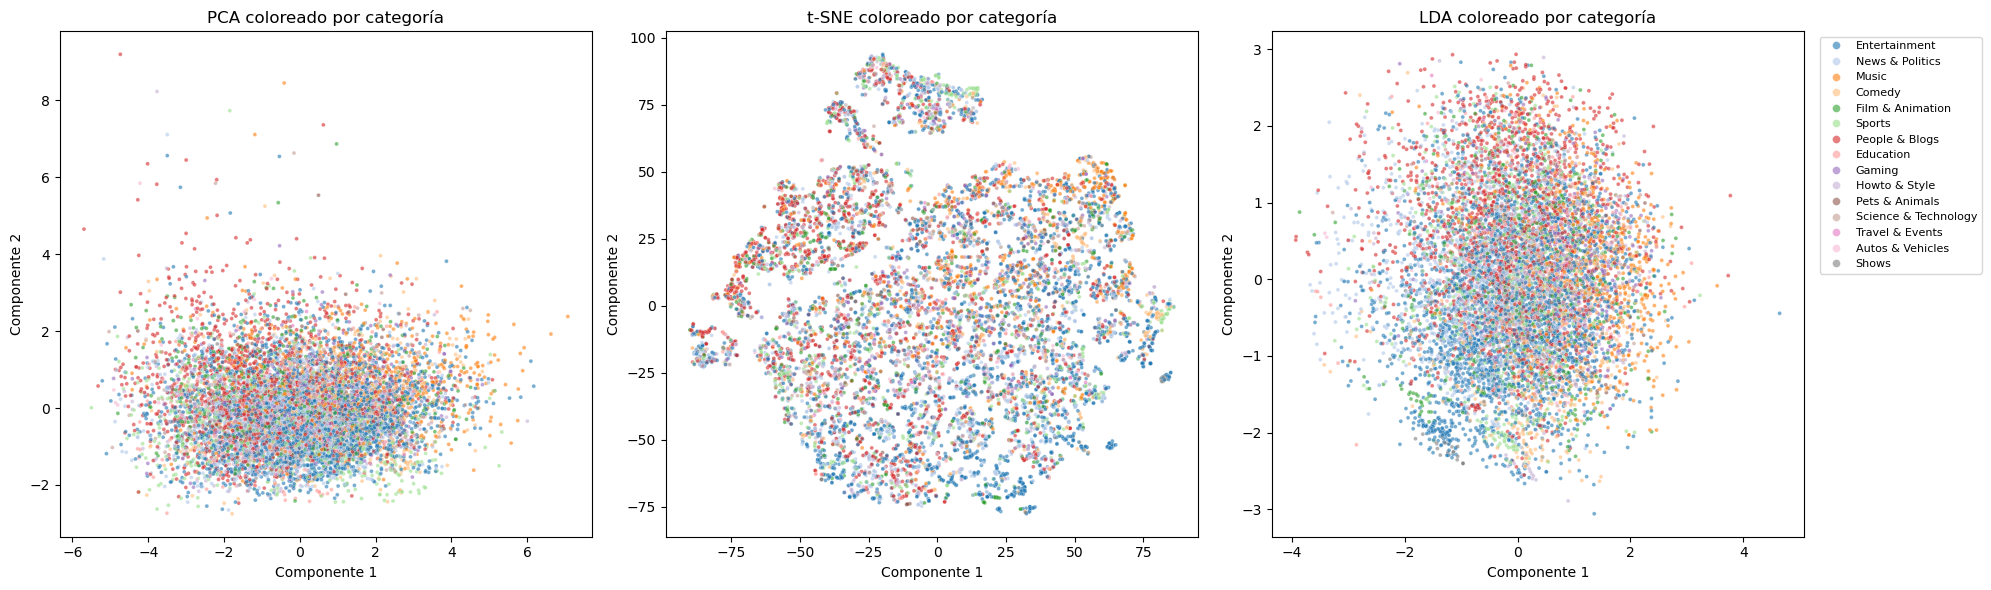

In [92]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

reducciones = {"PCA": X_pca, "t-SNE": X_tsne, "LDA": X_lda}

for ax, (nombre, X_red) in zip(axes, reducciones.items()):
    sns.scatterplot(x=X_red[:, 0], y=X_red[:, 1], hue=y_cluster.values, palette="tab20", s=8, alpha=0.6, legend=(nombre == "LDA"), ax=ax)
    ax.set_title(f"{nombre} coloreado por categoría")
    ax.set_xlabel("Componente 1")
    ax.set_ylabel("Componente 2")

axes[2].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, markerscale=2)

plt.tight_layout()
plt.show()

**¿Con qué reducción nos quedamos?**

Nos quedamos con **PCA** para clusterizar, por dos motivos:

- **Es la única de las tres sobre la que se puede clusterizar.** t-SNE deforma las distancias entre los vídeos, así que sirve para dibujarlos pero no para agruparlos. LDA usa la categoría para construirse, por lo que agrupar sobre ella sería darle la respuesta.
- **Muestra los datos tal como son.** Los vídeos forman una única nube compacta, sin grupos separados: la mayoría están concentrados en la parte de abajo y unos pocos se alejan hacia arriba (vídeos con valores extremos). Con solo 2 componentes conserva el 60% de la información.

En los tres gráficos las categorías salen mezcladas. Incluso LDA, que conoce la categoría, apenas consigue separarlas: solo se intuye que Music tiende hacia la derecha, People & Blogs hacia arriba y Entertainment hacia abajo. Por eso no esperamos que los clusters coincidan mucho con las categorías.

**K-Means**

K-Means necesita que le digamos de antemano cuántos grupos (k) tiene que formar. Para elegirlo probamos valores de k entre 2 y 10 y nos fijamos en dos cosas:

- **Inercia (método del codo):** mide lo cerca que están los vídeos del centro de su grupo. Siempre baja al aumentar k, así que buscamos el punto donde deja de bajar con fuerza (el "codo"), ya que a partir de ahí añadir más grupos apenas mejora.
- **Silhouette:** mide si cada vídeo está más cerca de los de su grupo que de los del grupo vecino. Va de -1 a 1 y cuanto mayor, mejor separados están los grupos.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [ ]:
valores_k = range(2, 11)
inercias = []
siluetas = []

for k in valores_k:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiquetas = kmeans.fit_predict(X_pca)
    inercias.append(kmeans.inertia_)
    siluetas.append(silhouette_score(X_pca, etiquetas))

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(valores_k, inercias, marker="o")
axes[0].set_title("Método del codo")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inercia")

axes[1].plot(valores_k, siluetas, marker="o")
axes[1].set_title("Silhouette")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

In [ ]:
k_elegido = 4#provisional: lo fijamos al ver el codo y la silhouette

kmeans = KMeans(n_clusters=k_elegido, n_init=10, random_state=42)
etiquetas_kmeans = kmeans.fit_predict(X_pca)

**DBSCAN**

DBSCAN agrupa los vídeos que están en zonas con muchos vídeos juntos, y los que quedan aislados los marca como ruido (etiqueta -1). No hay que decirle cuántos grupos formar, pero sí dos parámetros:

- **min_samples:** cuántos vídeos tiene que haber alrededor de un punto para considerar que está en una zona densa. Usamos 20.
- **eps:** el radio en el que se buscan esos vecinos. Para elegirlo calculamos, para cada vídeo, la distancia a su vecino número 20, las ordenamos de menor a mayor y las dibujamos. El punto donde la curva se dispara (el "codo") es un buen valor de eps: por debajo están los vídeos de zonas densas y por encima los aislados.

In [ ]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

In [ ]:
min_samples = 20

vecinos = NearestNeighbors(n_neighbors=min_samples).fit(X_pca)
distancias, _ = vecinos.kneighbors(X_pca)
distancias_k = np.sort(distancias[:, -1])#distancia de cada vídeo a su vecino número 20, ordenadas

plt.figure(figsize=(8, 5))
plt.plot(distancias_k)
plt.title("Distancia al vecino número 20")
plt.xlabel("Vídeos ordenados")
plt.ylabel("Distancia (eps)")
plt.show()

In [ ]:
eps_elegido = 0.3#provisional: lo fijamos al ver el codo del gráfico

dbscan = DBSCAN(eps=eps_elegido, min_samples=min_samples)
etiquetas_dbscan = dbscan.fit_predict(X_pca)

**Gaussian Mixture Models (GMM)**

GMM supone que los vídeos vienen de varios grupos con forma de campana (distribuciones normales) y calcula la probabilidad de que cada vídeo pertenezca a cada grupo; al final asignamos cada vídeo al grupo más probable. Igual que K-Means, hay que decirle cuántos grupos formar.

Para elegirlo usamos el **BIC**: mide lo bien que el modelo se ajusta a los datos, pero penaliza usar demasiados grupos. Probamos de 2 a 10 grupos y nos quedamos con el que tenga el BIC más bajo, o con el punto a partir del cual apenas baja.

In [ ]:
from sklearn.mixture import GaussianMixture

In [ ]:
valores_n = range(2, 11)
bics = []

for n in valores_n:
    gmm = GaussianMixture(n_components=n, random_state=42)
    gmm.fit(X_pca)
    bics.append(gmm.bic(X_pca))

plt.figure(figsize=(8, 5))
plt.plot(valores_n, bics, marker="o")
plt.title("BIC según el número de grupos")
plt.xlabel("Número de grupos")
plt.ylabel("BIC")
plt.show()

In [ ]:
n_grupos_gmm = 4#provisional: lo fijamos al ver el gráfico del BIC

gmm = GaussianMixture(n_components=n_grupos_gmm, random_state=42)
etiquetas_gmm = gmm.fit_predict(X_pca)

**HDBSCAN**

HDBSCAN funciona como DBSCAN (agrupa zonas densas y marca como ruido los vídeos aislados), pero no necesita eps: prueba él mismo distintos radios y se queda con los grupos más estables. Solo le indicamos **min_cluster_size**, el tamaño mínimo que tiene que tener un grupo para considerarlo como tal. Usamos 100 vídeos, para no obtener grupos demasiado pequeños sin interés.

In [ ]:
from sklearn.cluster import HDBSCAN

hdbscan = HDBSCAN(min_cluster_size=100)
etiquetas_hdbscan = hdbscan.fit_predict(X_pca)

**Comparativa de los modelos de clusterización**

Comparamos los cuatro modelos con estas métricas:

- **Nº de clusters** y **% de ruido:** cuántos grupos forma cada modelo y qué parte de los vídeos deja sin grupo (solo DBSCAN y HDBSCAN marcan ruido).
- **Silhouette:** si los grupos están bien separados entre sí. Va de -1 a 1, cuanto mayor mejor.
- **Davies-Bouldin:** también mide la separación de los grupos, pero cuanto menor mejor.
- **ARI y NMI:** cuánto se parecen los grupos a las categorías reales de los vídeos, que es lo que pide el enunciado. Valen 0 si no se parecen nada y 1 si coinciden por completo.

En DBSCAN y HDBSCAN calculamos la silhouette y el Davies-Bouldin sin los vídeos marcados como ruido, ya que no pertenecen a ningún grupo.

In [ ]:
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score

In [ ]:
def metricas_cluster(nombre, etiquetas):
    sin_ruido = etiquetas != -1#DBSCAN y HDBSCAN marcan el ruido con -1
    n_clusters = len(set(etiquetas[sin_ruido]))

    if n_clusters >= 2:#silhouette y Davies-Bouldin necesitan al menos 2 grupos
        silueta = silhouette_score(X_pca[sin_ruido], etiquetas[sin_ruido])
        davies_bouldin = davies_bouldin_score(X_pca[sin_ruido], etiquetas[sin_ruido])
    else:
        silueta = np.nan
        davies_bouldin = np.nan

    return {
        "Modelo": nombre,
        "Nº clusters": n_clusters,
        "% ruido": 100 * (etiquetas == -1).mean(),
        "Silhouette": silueta,
        "Davies-Bouldin": davies_bouldin,
        "ARI": adjusted_rand_score(y_cluster, etiquetas),
        "NMI": normalized_mutual_info_score(y_cluster, etiquetas)
    }

In [ ]:
df_clusters = pd.DataFrame([
    metricas_cluster("K-Means", etiquetas_kmeans),
    metricas_cluster("DBSCAN", etiquetas_dbscan),
    metricas_cluster("GMM", etiquetas_gmm),
    metricas_cluster("HDBSCAN", etiquetas_hdbscan)
])

df_clusters = df_clusters.sort_values(by="Silhouette", ascending=False)

tabla_clusters = df_clusters.style

tabla_clusters = tabla_clusters.highlight_max(subset=["Silhouette", "ARI", "NMI"], props="font-weight: bold; font-size: 16px;")#cuanto mayor mejor
tabla_clusters = tabla_clusters.highlight_min(subset=["Davies-Bouldin"], props="font-weight: bold; font-size: 16px;")#cuanto menor mejor

tabla_clusters.hide()#ocultamos el indice

Dibujamos los grupos de cada modelo sobre el mismo gráfico de PCA de antes, para compararlos con el gráfico coloreado por categoría. En DBSCAN y HDBSCAN el grupo -1 son los vídeos marcados como ruido.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

modelos_cluster = {"K-Means": etiquetas_kmeans, "DBSCAN": etiquetas_dbscan, "GMM": etiquetas_gmm, "HDBSCAN": etiquetas_hdbscan}

for ax, (nombre, etiquetas) in zip(axes.flatten(), modelos_cluster.items()):
    sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=etiquetas, palette="tab10", s=8, alpha=0.6, ax=ax)
    ax.set_title(f"{nombre} sobre PCA")
    ax.set_xlabel("Componente 1")
    ax.set_ylabel("Componente 2")
    ax.legend(title="Cluster", fontsize=8, markerscale=2)

plt.tight_layout()
plt.show()

**Crear un recomendador**

""title: El título del video en formato de texto original libre (tal y como lo escribió el creador, incluyendo emojis, mayúsculas y caracteres especiales). 

channel_title: El nombre original del canal de YouTube que subió el video.  

category_id: El identificador de la categoría asignada al video. Actualizado más arriba por el país en cuestión. 

tags: Las palabras clave asociadas al video. 

views: La cantidad de reproducciones acumuladas que registraba el video en ese día específico en que apareció en tendencias.  

likes: La cantidad de votos "Me gusta" acumulados que tenía el video en ese día específico.  

dislikes: La cantidad de votos "No me gusta" acumulados que tenía el video en ese día específico.  

comment_count: El número de comentarios totales escritos por los usuarios en ese día específico.  

comments_disabled: Un interruptor lógico (True/False) que indica si el canal tenía los comentarios desactivados en ese momento.  

ratings_disabled: Un interruptor lógico (True/False) que indica si el canal tenía ocultos los contadores de likes/dislikes en ese momento.  

video_error_or_removed: Un interruptor lógico (True/False) que indica si el video fue borrado o tuvo un error mientras estaba en la lista de tendencias.  

description: El texto explicativo original largo que el creador colocó en la caja de descripción del video. 

pais: El país donde se obtuvo el dato.

Estos son los items que tendremos que predecir:  
1.Prediga la categoría del vídeo  
2.Predecir el número de likes  
3.Encontrar grupos en los vídeos mediante diversas técnicas de clusterización  
4.Crear un recomendador

[('title', 'string'), 
 ('channel_title', 'string'),
 ('pais', 'string'),
 ('views', 'int'),
 ('tags', 'string'),
 ('likes', 'int'),
 ('dislikes', 'int'),
 ('comment_count', 'int'),
 ('comments_disabled', 'boolean'),
 ('ratings_disabled', 'boolean'),
 ('video_error_or_removed', 'boolean'),
 ('description', 'string'),
 ('category', 'string'),
 ('month_trending', 'int'),
 ('month_publish', 'int')]"""
 • ¿Estás clasificando categorías? Usa Regresión Logística, Árboles de decisión, KNN o SVM.
• ¿Estás prediciendo un número? Usa Regresión Lineal o Árboles de decisión (Regresores).
• ¿Tus datos no tienen etiquetas (no sabes la respuesta)? Usa Clustering o Reducción de dimensionalidad.